## Key Observations and Findings

1. Unemployment rates fluctuated over the analysed period.
2. Different Indian regions showed different average unemployment rates.
3. The COVID-19 period had a noticeable impact on unemployment.
4. Rural and urban areas showed differences in unemployment rates.
5. Labour participation changed over time.
6. The correlation heatmap helped identify relationships between employment-related variables.
7. Regional comparisons highlighted areas with relatively higher unemployment rates.

## Conclusion

This project analysed unemployment trends in India using Python.
Data cleaning, statistical analysis and visualisations were
performed using Pandas, NumPy, Matplotlib and Seaborn.

The analysis helped identify regional differences, monthly
trends and changes during the COVID-19 period.

Dataset 2 - Average Unemployment Rate by Region:


Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64

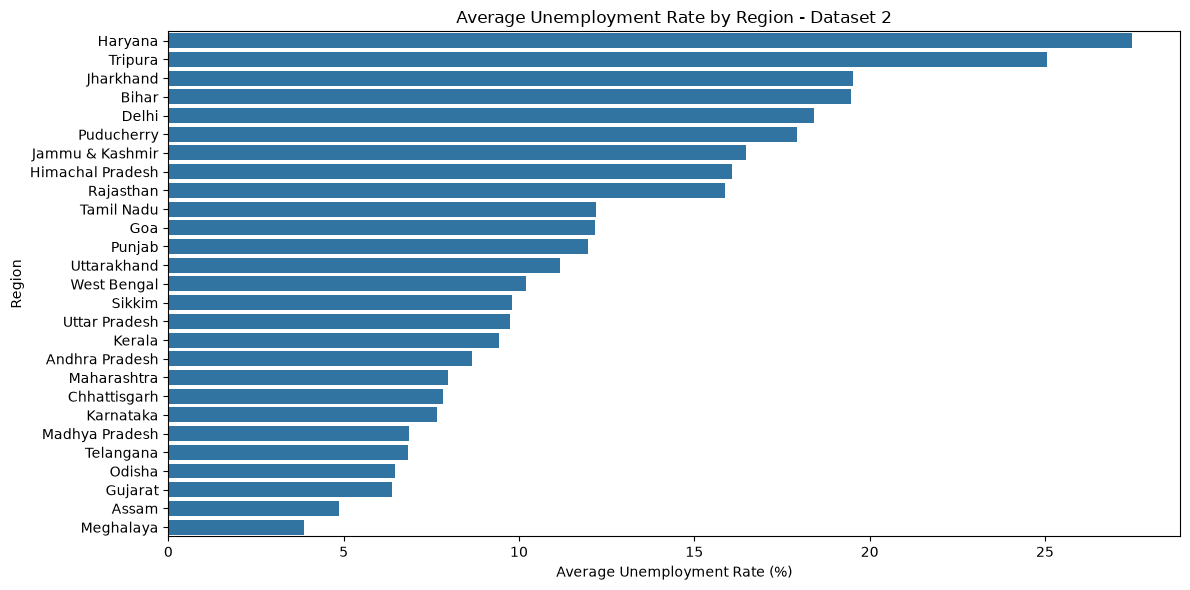

In [21]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset 2
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

# Clean column names
df2.columns = df2.columns.str.strip()

# Convert Date column
df2['Date'] = pd.to_datetime(
    df2['Date'],
    dayfirst=True,
    errors='coerce'
)

# Remove missing values
df2 = df2.dropna()

# Calculate average unemployment rate by region
region_comparison = (
    df2.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

# Display results
print("Dataset 2 - Average Unemployment Rate by Region:")
display(region_comparison)

# Create bar graph
plt.figure(figsize=(12, 6))

sns.barplot(
    x=region_comparison.values,
    y=region_comparison.index
)

plt.title('Average Unemployment Rate by Region - Dataset 2')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.tight_layout()
plt.show()


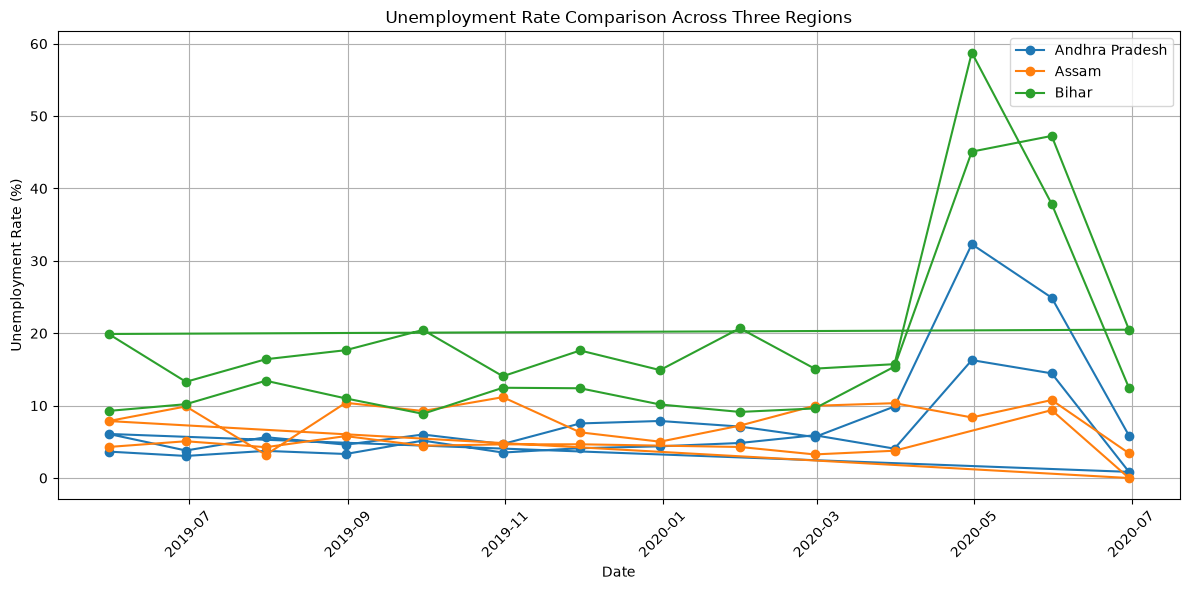

In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both datasets
df1 = pd.read_csv("Unemployment in India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

# Clean column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Convert dates
df1['Date'] = pd.to_datetime(df1['Date'], dayfirst=True, errors='coerce')
df2['Date'] = pd.to_datetime(df2['Date'], dayfirst=True, errors='coerce')

# Remove missing values
df1 = df1.dropna()
df2 = df2.dropna()

# Compare unemployment across three regions
top_regions = df1['Region'].unique()[:3]

plt.figure(figsize=(12, 6))

for region in top_regions:
    region_data = df1[df1['Region'] == region]

    plt.plot(
        region_data['Date'],
        region_data['Estimated Unemployment Rate (%)'],
        marker='o',
        label=region
    )

plt.title('Unemployment Rate Comparison Across Three Regions')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


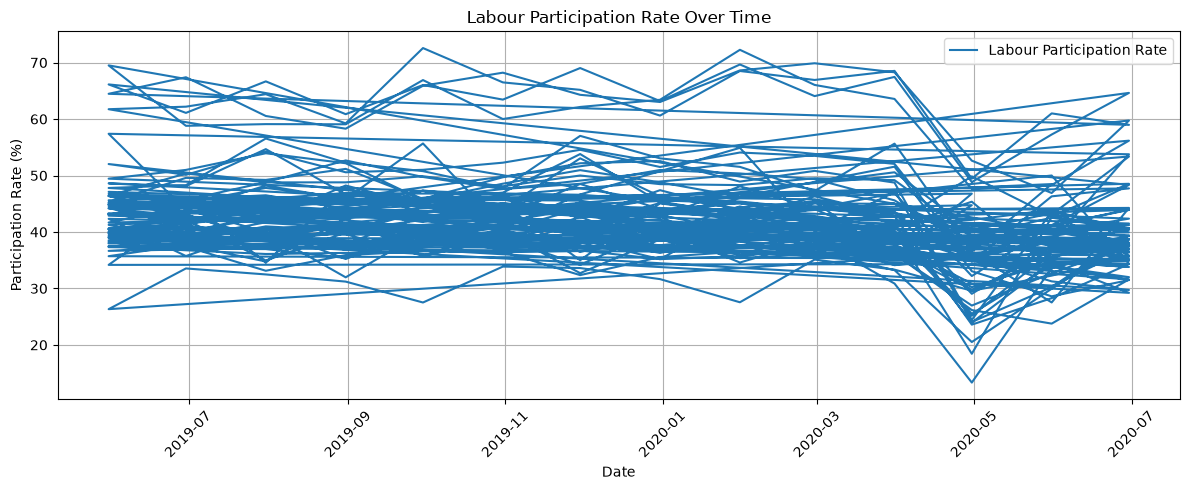

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    df1['Date'],
    df1['Estimated Labour Participation Rate (%)'],
    label='Labour Participation Rate'
)

plt.title('Labour Participation Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Participation Rate (%)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Average Unemployment Rate by Area:


Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

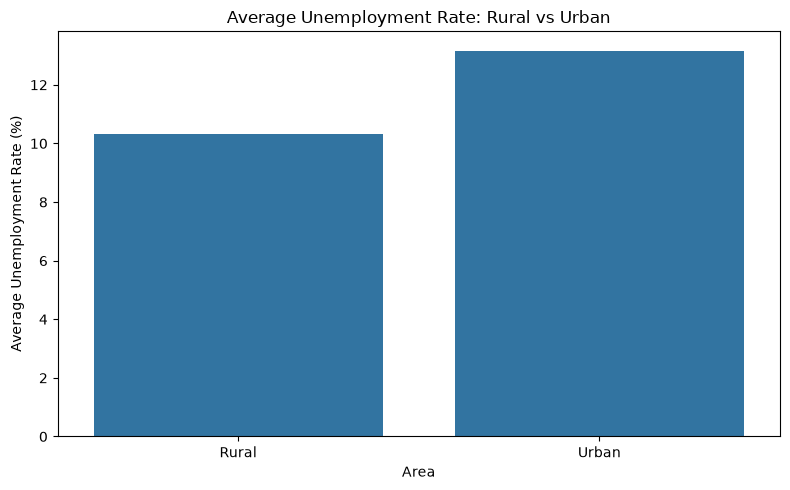

In [24]:
area_comparison = df1.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Average Unemployment Rate by Area:")
display(area_comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_comparison.index,
    y=area_comparison.values
)

plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

Average Unemployment Rate Comparison:


COVID_Period
Before COVID           9.509534
During/After COVID    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64

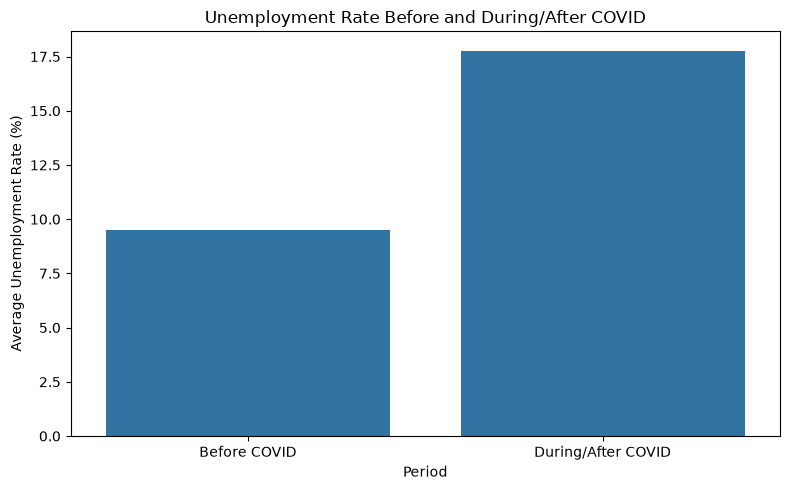

In [25]:
df1['COVID_Period'] = np.where(
    df1['Date'] < '2020-03-01',
    'Before COVID',
    'During/After COVID'
)

covid_comparison = df1.groupby('COVID_Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Average Unemployment Rate Comparison:")
display(covid_comparison)

plt.figure(figsize=(8, 5))
sns.barplot(x=covid_comparison.index, y=covid_comparison.values)

plt.title('Unemployment Rate Before and During/After COVID')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

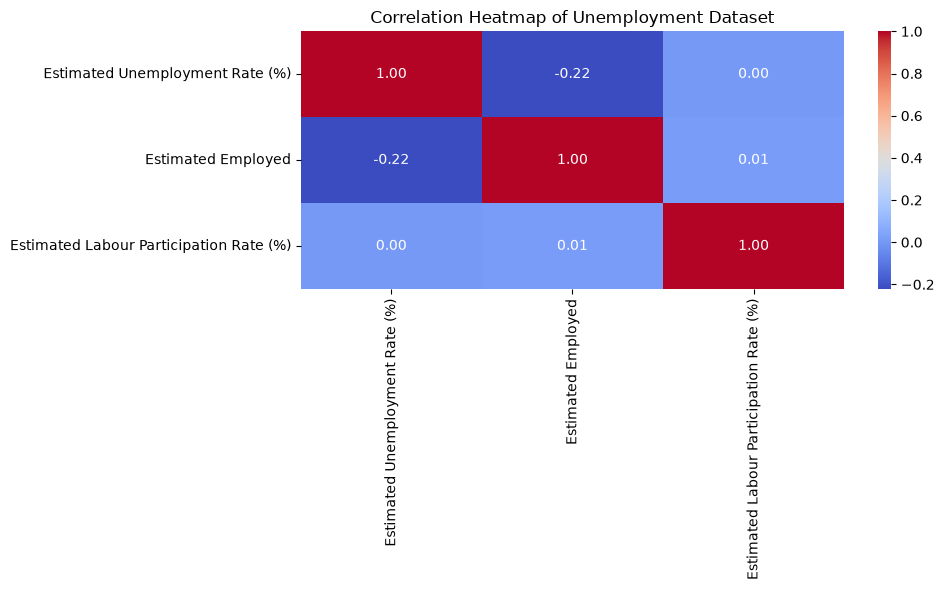

In [26]:
plt.figure(figsize=(10, 6))

numeric_data = df1.select_dtypes(include=np.number)

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Unemployment Dataset')
plt.tight_layout()
plt.show()

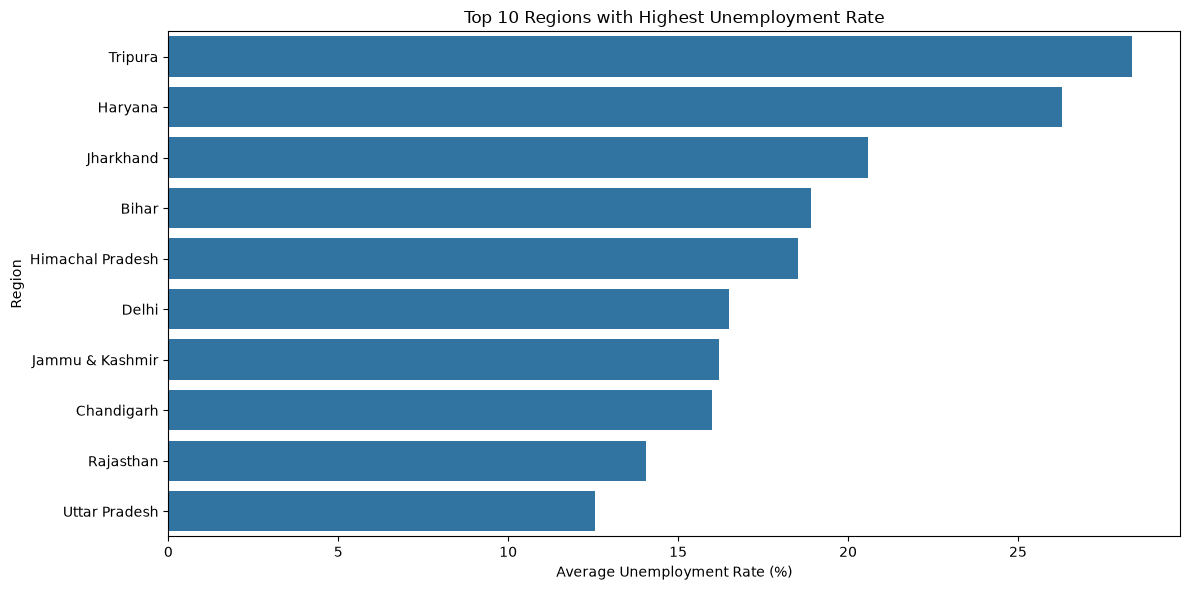

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

In [27]:
top_10 = (
    df1.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_10.values, y=top_10.index)

plt.title('Top 10 Regions with Highest Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

display(top_10)

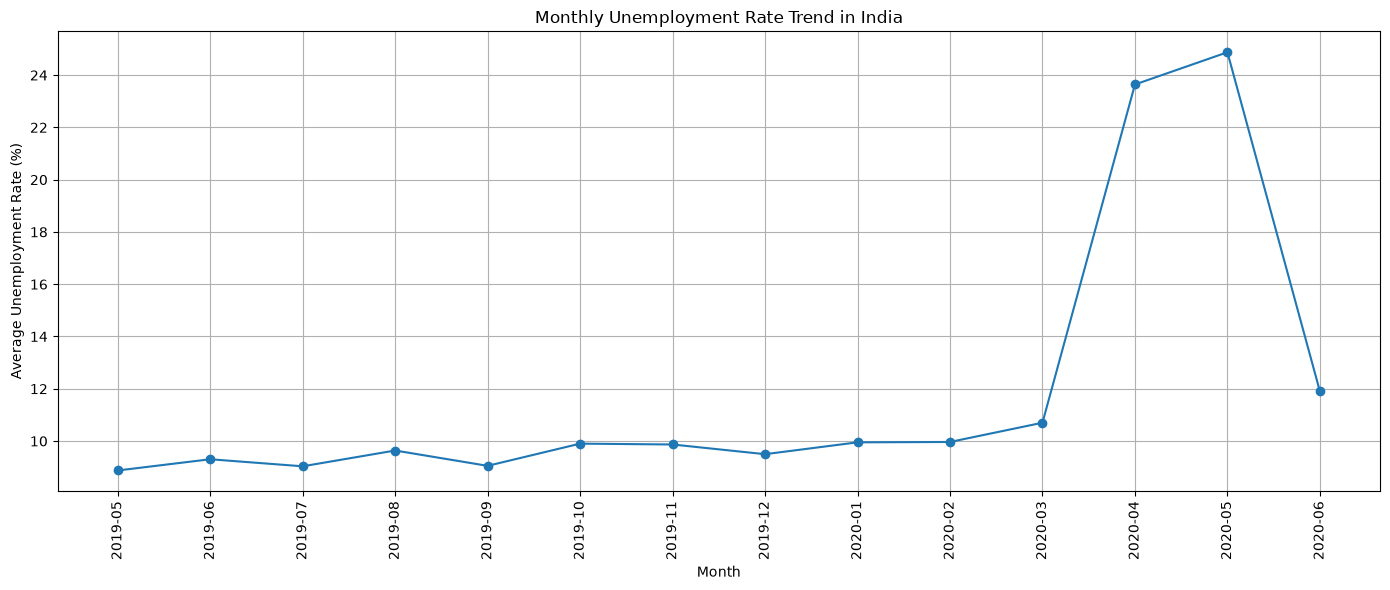

In [28]:
# Extract month and year
df1['Month'] = df1['Date'].dt.to_period('M')

# Calculate monthly average unemployment rate
monthly_data = df1.groupby('Month')['Estimated Unemployment Rate (%)'].mean()

# Plot monthly trend
plt.figure(figsize=(14, 6))

plt.plot(monthly_data.index.astype(str), monthly_data.values, marker='o')

plt.title('Monthly Unemployment Rate Trend in India')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

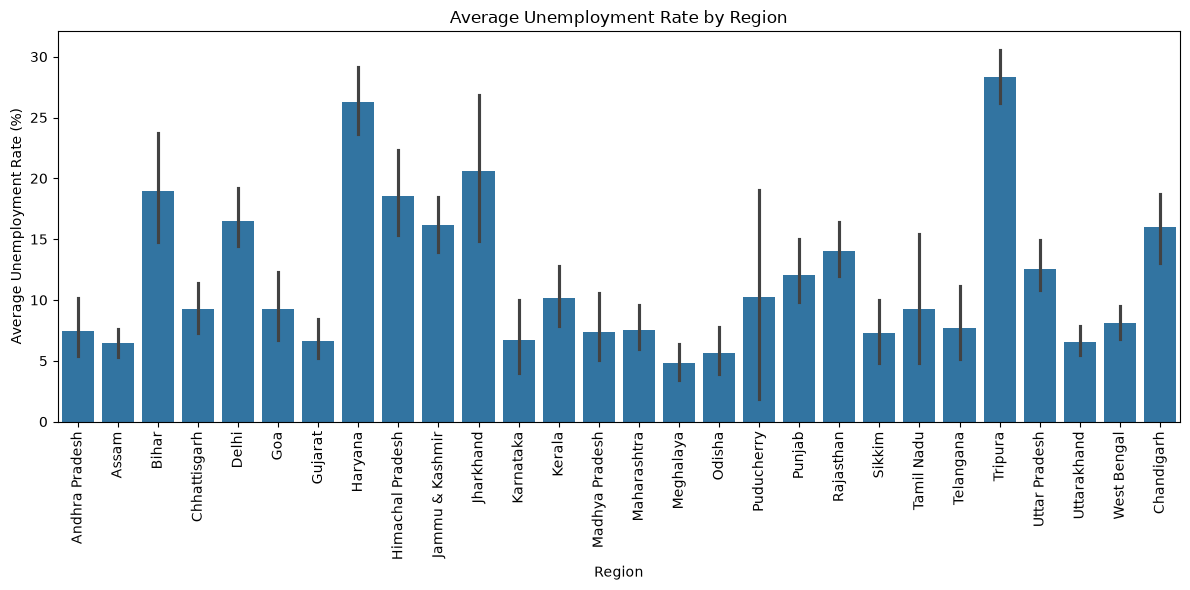

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df1,
    x='Region',
    y='Estimated Unemployment Rate (%)',
    estimator='mean'
)

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

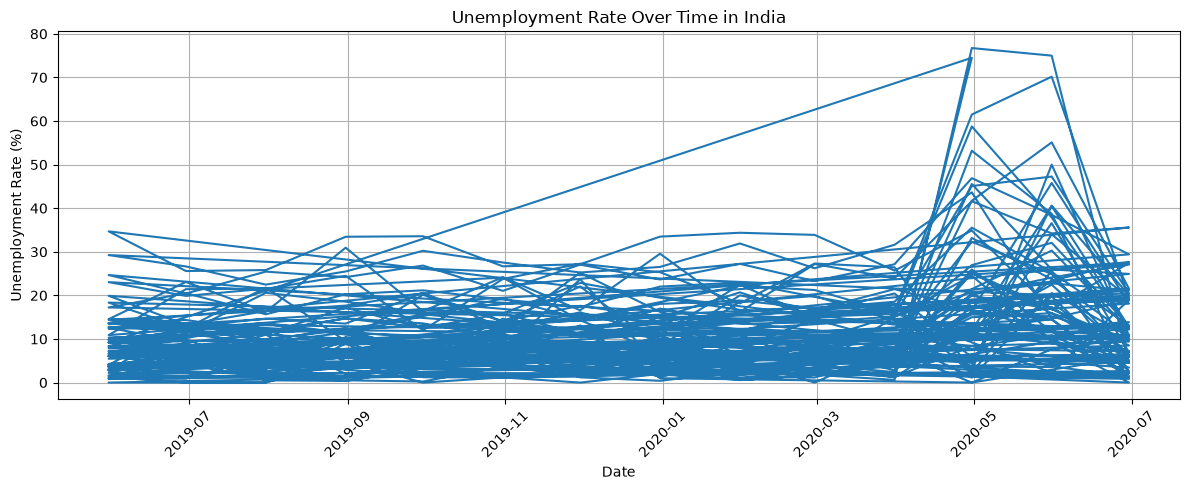

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(df1['Date'], df1['Estimated Unemployment Rate (%)'])

plt.title('Unemployment Rate Over Time in India')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
# Sort both datasets by date
df1 = df1.sort_values(by='Date')
df2 = df2.sort_values(by='Date')

# Display the latest records
print("Dataset 1 - Latest Records:")
display(df1.tail())

print("Dataset 2 - Latest Records:")
display(df2.tail())

Dataset 1 - Latest Records:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,COVID_Period,Month
275,Sikkim,2020-06-30,Monthly,5.81,141313.0,42.36,Rural,During/After COVID,2020-06
289,Tamil Nadu,2020-06-30,Monthly,2.06,10169115.0,31.49,Rural,During/After COVID,2020-06
303,Telangana,2020-06-30,Monthly,19.30,8891181.0,58.97,Rural,During/After COVID,2020-06
121,Himachal Pradesh,2020-06-30,Monthly,1.12,2230075.0,41.20,Rural,During/After COVID,2020-06
753,West Bengal,2020-06-30,Monthly,9.86,9088931.0,37.57,Urban,During/After COVID,2020-06


Dataset 2 - Latest Records:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
19,Assam,2020-10-31,M,3.02,11949329,46.84,Northeast,26.2006,92.9376
178,Puducherry,2020-10-31,M,6.18,428419,36.32,South,11.9416,79.8083
79,Haryana,2020-10-31,M,27.31,6698551,40.60,North,29.0588,76.0856
59,Goa,2020-10-31,M,11.54,392304,34.30,West,15.2993,74.1240
266,West Bengal,2020-10-31,M,9.98,33962549,45.63,East,22.9868,87.8550


In [32]:
# Remove rows with missing values
df1 = df1.dropna()
df2 = df2.dropna()

print("Dataset 1 after cleaning:", df1.shape)
print("Dataset 2 after cleaning:", df2.shape)

print("\nRemaining missing values in Dataset 1:")
print(df1.isnull().sum())

print("\nRemaining missing values in Dataset 2:")
print(df2.isnull().sum())

Dataset 1 after cleaning: (740, 9)
Dataset 2 after cleaning: (267, 9)

Remaining missing values in Dataset 1:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
COVID_Period                               0
Month                                      0
dtype: int64

Remaining missing values in Dataset 2:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


In [33]:
# Convert Date columns into datetime format
df1['Date'] = pd.to_datetime(df1['Date'], dayfirst=True, errors='coerce')
df2['Date'] = pd.to_datetime(df2['Date'], dayfirst=True, errors='coerce')

print("Dataset 1 Date Range:")
print(df1['Date'].min(), "to", df1['Date'].max())

print("\nDataset 2 Date Range:")
print(df2['Date'].min(), "to", df2['Date'].max())

Dataset 1 Date Range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Dataset 2 Date Range:
2020-01-31 00:00:00 to 2020-10-31 00:00:00


In [34]:
print("Dataset 1 Data Types:")
print(df1.dtypes)

print("\nDataset 2 Data Types:")
print(df2.dtypes)

Dataset 1 Data Types:
Region                                                str
Date                                       datetime64[us]
Frequency                                             str
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                                  str
COVID_Period                                          str
Month                                           period[M]
dtype: object

Dataset 2 Data Types:
Region                                                str
Date                                       datetime64[us]
Frequency                                             str
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                  int64
Estimated Labour Participation Rate (%)           float64
Region.1                                              str
longitude    

In [35]:
# Remove extra spaces from column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

print("Cleaned Dataset 1 Columns:")
print(df1.columns.tolist())

print("\nCleaned Dataset 2 Columns:")
print(df2.columns.tolist())

Cleaned Dataset 1 Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'COVID_Period', 'Month']

Cleaned Dataset 2 Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [36]:
# Statistical summary of Dataset 1
print("Dataset 1 Statistical Summary:")
display(df1.describe())

# Statistical summary of Dataset 2
print("Dataset 2 Statistical Summary:")
display(df2.describe())

Dataset 1 Statistical Summary:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


Dataset 2 Statistical Summary:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,2020-06-16 09:15:30.337078,12.236929,1.396211e+07,41.681573,22.826048,80.532425
min,2020-01-31 00:00:00,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,2020-03-31 00:00:00,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,2020-06-30 00:00:00,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,2020-08-31 00:00:00,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,2020-10-31 00:00:00,75.850000,5.943376e+07,69.690000,33.778200,92.937600
std,NaN,10.803283,1.336632e+07,7.845419,6.270731,5.831738


In [37]:
print("DATASET 1 INFORMATION")
df1.info()

print("\nDATASET 2 INFORMATION")
df2.info()

DATASET 1 INFORMATION
<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    str           
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    str           
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    str           
 7   COVID_Period                             740 non-null    str           
 8   Month                                    740 non-null    period[M]     
dtypes: datetime64[us](1), float64(3), peri

In [38]:
# Check missing values in Dataset 1
print("Missing Values in Dataset 1:")
print(df1.isnull().sum())

# Check missing values in Dataset 2
print("\nMissing Values in Dataset 2:")
print(df2.isnull().sum())


Missing Values in Dataset 1:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
COVID_Period                               0
Month                                      0
dtype: int64

Missing Values in Dataset 2:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


In [39]:
print("Dataset 1 Shape:", df1.shape)
print("\nDataset 1 Columns:")
print(df1.columns.tolist())

print("\nDataset 2 Shape:", df2.shape)
print("\nDataset 2 Columns:")
print(df2.columns.tolist())

Dataset 1 Shape: (740, 9)

Dataset 1 Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'COVID_Period', 'Month']

Dataset 2 Shape: (267, 9)

Dataset 2 Columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both CSV datasets
df1 = pd.read_csv("Unemployment in India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

# Display first five rows of both datasets
print("Dataset 1:")
display(df1.head())

print("Dataset 2:")
display(df2.head())

Dataset 1:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Dataset 2:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74
